### Note: The following notebook has been used to generate the plots for the website on RQ2 part.

In [10]:
# Imports
import sys
import os
project_root = os.path.abspath(os.path.join(os.getcwd(), '../..'))

if project_root not in sys.path:
    sys.path.insert(0, project_root)

from scipy.stats import mannwhitneyu
from src.data.loader import load_all_raw_datasets, iterate_parquet_stream
from src.data.preprocessing import apply_data_processing
from src.data.quality_check import check_data_quality_on_datasets
from src.models.log_log_efficiency_model import linear_log_log_model
from src.models.topic_labeling import generate_topic_labels
from src.utils.text_utils import preprocess_and_build_gensim_corpus, clean_and_tokenize_tags
from src.utils.general_utils import weighted_percentiles
from config import (
    DATASET_CHANNELS,
    DATASET_TIMESERIES,
    DATASET_VIDEO_LIGHT,
    DATASET_TAGS,
    CACHED_RESUTLS_DIR
)
from src.utils.plots import *
import pandas as pd
import numpy as np
from collections import Counter, defaultdict
import os
import joblib
from gensim.models import LdaModel
from gensim.corpora import Dictionary
import zlib
from tqdm import tqdm
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt
from src.utils.text_utils import *

from scipy.stats import chi2_contingency

sns.set_style("whitegrid")
sns.set_palette("husl")
seed = 6

%load_ext autoreload
%autoreload 2
%reload_ext autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In this research question, our goal is to study how engagement efficiency varies across different content topics on YouTube and if quiet outperformers concentrated in particular content categories.

We use creator-assigned video tags for topic detection, rather than titles or descriptions. Tags are concise, creator-curated signals that better capture semantic intent, reduce textual noise, and scale efficiently to the large size of the YouNiverse dataset.

**Data subsampling for training**: Due to the large scale of the YouNiverse dataset, training on all videos is computationally infeasible. We therefore apply stratified sampling to ensure manageable runtime and to ensure that all content categories are represented. Sampling is performed independently within each data chunk and proportionally across years, ensuring that all content categories are represented and that temporal coverage remains balanced (e.g., early, mid, and recent years are evenly covered).

In [2]:
# Counts how many videos exists for each category

category_counts = Counter()

for df_chunk in iterate_parquet_stream(DATASET_VIDEO_LIGHT, window_size=10_000_000):
    cats = df_chunk["categories"].astype(str)
    category_counts.update(cats)

category_counts

++ Final chunk: rows 70,647,808-72,924,794 | rows=2,276,986 | total=72,924,794


Counter({'Gaming': 13720303,
         'Entertainment': 12276397,
         'News & Politics': 8881022,
         'Music': 8305003,
         'People & Blogs': 6910666,
         'Sports': 4354412,
         'Howto & Style': 3968127,
         'Education': 3795564,
         'Science & Technology': 2403004,
         'Film & Animation': 2359736,
         'Autos & Vehicles': 2256967,
         'Comedy': 1172503,
         'Travel & Events': 1096565,
         'Nonprofits & Activism': 777449,
         'Pets & Animals': 645508,
         '': 1522,
         'Shows': 41,
         'Movies': 5})

In [3]:
# Drop legacy / weird categories
RARE_CATEGORIES = {"", "Shows", "Movies"}

# Minimum size for a category to be considered in stratified sampling
MIN_VIDEOS_FOR_CATEGORY = 10_000  

# Max sampled videos per category
MAX_PER_CATEGORY = 40_000       

# Build dict of sampling targets per category
target_per_cat = {}
for cat, count in category_counts.items():
    if cat in RARE_CATEGORIES:
        continue     
    if count < MIN_VIDEOS_FOR_CATEGORY:
        continue      
    target_per_cat[cat] = min(MAX_PER_CATEGORY, count)

target_per_cat

{'Film & Animation': 40000,
 'Gaming': 40000,
 'Education': 40000,
 'People & Blogs': 40000,
 'Entertainment': 40000,
 'Autos & Vehicles': 40000,
 'Comedy': 40000,
 'Sports': 40000,
 'News & Politics': 40000,
 'Music': 40000,
 'Howto & Style': 40000,
 'Science & Technology': 40000,
 'Travel & Events': 40000,
 'Pets & Animals': 40000,
 'Nonprofits & Activism': 40000}

In [4]:
# To avoid bias when iterating
rates = {
    cat: (target_per_cat[cat] / category_counts[cat]) * 1.05  # Dont fall short
    for cat in target_per_cat
}

sampled_video_rows = []


for df_chunk in tqdm(iterate_parquet_stream(DATASET_VIDEO_LIGHT, window_size=10_000_000)):
    df_chunk["categories"] = df_chunk["categories"].astype(str)
    
    # Filter to only categories we want
    df_chunk = df_chunk[df_chunk["categories"].isin(target_per_cat.keys())]
    
    for cat, group in df_chunk.groupby("categories"):
        # Take a fixed % from EVERY chunk -> Gets 2010, 2015, 2024 equally
        
        take_n = int(len(group) * rates[cat])
        
        if take_n > 0:
            sampled_video_rows.append(
                group.sample(n=take_n, random_state=0)[["display_id", "channel_id", "categories"]]
            )

# Combine and Trim
sampled_videos = pd.concat(sampled_video_rows, ignore_index=True)

# Because we took a % from every chunk, we might have slightly too many.
# Trim down to the exact target number randomly.
sampled_videos = sampled_videos.groupby('categories', group_keys=False).apply(
    lambda x: x.sample(n=min(len(x), target_per_cat[x.name]), random_state=0)
)

print("Sampled videos:", len(sampled_videos))
sampled_videos.head()
    


8it [01:24, 10.58s/it]


++ Final chunk: rows 70,647,808-72,924,794 | rows=2,276,986 | total=72,924,794
Sampled videos: 600000


C:\Users\Jon\AppData\Local\Temp\ipykernel_27148\2011477266.py:31: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sampled_videos = sampled_videos.groupby('categories', group_keys=False).apply(


,display_id,channel_id,categories
91335,XaHXgDYw_dQ,UCyEo2ZTCplRz6vRAQcOaoZg,Autos & Vehicles
175743,riVqriNCXdo,UCZ2eIJY0phalm_MG38kE26A,Autos & Vehicles
87583,31oWVd0iqWg,UChYNm1Gh6V9CmK3QY89rwPg,Autos & Vehicles
352550,ZKn_kHDojT8,UCIYCuTtugo3u4ks8azQJl5A,Autos & Vehicles
519692,8wT2dLuaxBU,UC6Uf3_BqRc6iaHC9Zn_D-lA,Autos & Vehicles


In [5]:
sampled_ids = set(sampled_videos["display_id"].unique())
len(sampled_ids)

600000

In [6]:

tag_rows = []

for df_chunk in tqdm(iterate_parquet_stream(DATASET_TAGS, window_size=1_000_000)):
    sub = df_chunk[df_chunk["display_id"].isin(sampled_ids)]
    if not sub.empty:
        tag_rows.append(sub[["display_id", "tags"]])

sampled_tags = pd.concat(tag_rows, ignore_index=True)
print("Sampled tag rows:", len(sampled_tags))
sampled_tags.head()

70it [02:41,  2.31s/it]

++ Final chunk: rows 72,393,216-72,924,794 | rows=531,578 | total=72,924,794
Sampled tag rows: 600000


,display_id,tags
0,qWMuC35RwjI,"lego city police,lego city,lego police,lego fi..."
1,4rvxj5EypU4,"imaginext,imaginext batman car,imaginext batca..."
2,JOdILXZKC30,"lego juniors,lego city,lego police,lego firema..."
3,VPqJmODeZyk,"lego city,lego police,lego city police,lego fi..."
4,mwqZsqVL-c0,"lego dinosaurs,dinosaurs for kids,lego dinosau..."


**Tag representation choices**: We considered two alternative strategies for processing video tags. 
1. tokenizes tags into individual words and bigrams, reducing reliance on creators using tags in a consistent or well-structured format. 
2. preserves each tag as a single unit by replacing spaces with underscores, thereby treating multi-word tags (e.g., “machine_learning”) as coherent semantic concepts reflecting creators’ intent.

For each tag representation strategy, we trained Latent Dirichlet Allocation (LDA) models across a range of topic numbers. We evaluated the resulting models using coherence scores and found that, for most topic counts, the representation preserving multi-word tags (via underscore replacement) achieved higher coherence. We therefore adopt this approach for downstream topic detection.

1. Bigram

In [11]:
sampled_merged = sampled_videos.merge(
    sampled_tags,
    on="display_id",
    how="inner"
)

print(f"Merged rows: {len(sampled_merged)}")
df_clean, dictionary, corpus = preprocess_and_build_gensim_corpus_bigram(sampled_merged, "tags")

Merged rows: 600000
Tokenizing 600000 rows (ignoring commas)...


100%|██████████| 600000/600000 [00:31<00:00, 19321.92it/s]


Training Bigram model (Phrases)...
Applying Bigrams to dataset...
Dropped 66167 rows with no valid tags.
Building gensim dictionary and corpus...


Creating corpus: 100%|██████████| 533833/533833 [00:12<00:00, 44035.33it/s]


Dictionary size: 21567, Corpus size: 533833


Training LDA with k=15 topics...

Coherence: 0.4709 | Time: 3.0 min
Training LDA with k=20 topics...

Coherence: 0.4339 | Time: 3.1 min
Training LDA with k=25 topics...

Coherence: 0.4348 | Time: 3.2 min
Training LDA with k=30 topics...

Coherence: 0.4289 | Time: 2.7 min
Training LDA with k=35 topics...

Coherence: 0.4094 | Time: 2.6 min
Training LDA with k=40 topics...

Coherence: 0.4324 | Time: 2.7 min

Grid Search Results:
 k  coherence  time_min
15   0.470861  2.983050
20   0.433937  3.084358
25   0.434813  3.248857
30   0.428869  2.680888
35   0.409364  2.567841
40   0.432446  2.664119

Best k: 15 (Coherence: 0.4709)


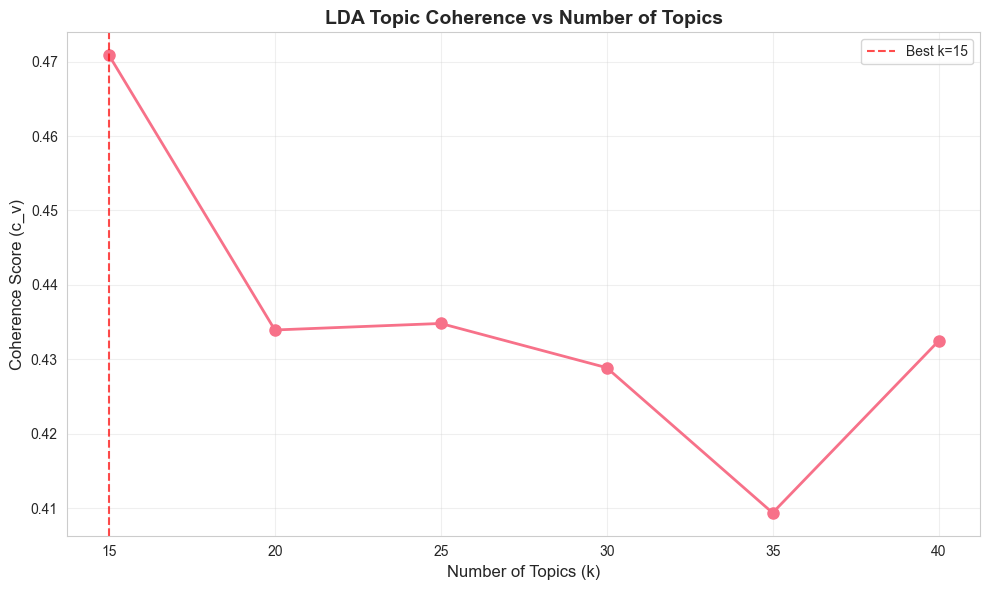

In [12]:
import multiprocessing
from gensim.models.coherencemodel import CoherenceModel
from gensim.models import LdaMulticore
import time

k_values = [15, 20, 25, 30, 35, 40]
coherence_scores = []
training_times = []

for k in k_values:
    print(f"Training LDA with k={k} topics...\n")
    
    start_time = time.time()
    
    lda_temp = LdaMulticore(
        corpus=corpus,
        id2word=dictionary,
        num_topics=k,
        passes=5,
        workers=multiprocessing.cpu_count() - 1,
        random_state=42,
        chunksize=2000
    )
    
    elapsed = time.time() - start_time
    training_times.append(elapsed)
    
    # Compute coherence score
    coherence_model = CoherenceModel(
        model=lda_temp,
        texts=df_clean['tags_tokens'],
        dictionary=dictionary,
        coherence='c_v'
    )
    coherence = coherence_model.get_coherence()
    coherence_scores.append(coherence)
    
    print(f"Coherence: {coherence:.4f} | Time: {elapsed/60:.1f} min")

# Results summary
results_df = pd.DataFrame({
    'k': k_values,
    'coherence': coherence_scores,
    'time_min': [t/60 for t in training_times]
})

print(f"\n{'='*50}")
print("Grid Search Results:")
print(f"{'='*50}")
print(results_df.to_string(index=False))

best_k = results_df.loc[results_df['coherence'].idxmax(), 'k']
print(f"\nBest k: {int(best_k)} (Coherence: {results_df['coherence'].max():.4f})")

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(k_values, coherence_scores, marker='o', linewidth=2, markersize=8)
ax.axvline(best_k, color='red', linestyle='--', alpha=0.7, label=f'Best k={int(best_k)}')
ax.set_xlabel('Number of Topics (k)', fontsize=12)
ax.set_ylabel('Coherence Score (c_v)', fontsize=12)
ax.set_title('LDA Topic Coherence vs Number of Topics', fontsize=14, fontweight='bold')
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [14]:
import time
from gensim.models import LdaMulticore

# Train final model with optimal k and higher passes for quality
print(f"Training final LDA model with k={int(best_k)} and passes=15...")
start_time = time.time()

lda = LdaMulticore(
    corpus=corpus,
    id2word=dictionary,
    num_topics=int(best_k),
    passes=15,
    workers=multiprocessing.cpu_count() - 1,
    random_state=42,
    per_word_topics=False,
    chunksize=2000
)

elapsed = time.time() - start_time
print(f"Final training complete in {elapsed/60:.1f} minutes")

# Display top words per topic
def print_top_words(model, n_top_words=15):
    for topic_idx in range(model.num_topics):
        top_words = [word for word, _ in model.show_topic(topic_idx, topn=n_top_words)]
        print(f"Topic #{topic_idx:02d}: {', '.join(top_words)}")

print(f"\nTop words for {int(best_k)} topics:")
print_top_words(lda)


Training final LDA model with k=15 and passes=15...
Final training complete in 6.4 minutes

Top words for 15 topics:
Topic #00: travel, tour, house, christmas, comedy, tourism, christian, holiday, festival, hotel, london, world, africa, church, party
Topic #01: india, football, sports, highlights, indian, team, business, fortnite, sport, philippines, world_cup, school, education, soccer, league
Topic #02: show, story, japan, star, podcast, stories, anime, death, real, man, series, piano, john, comedy, dead
Topic #03: dog, real_estate, animal, tips, dogs, pet, training, animals, science, fish, tutorial, tricks, cute, learn, pakistan_property
Topic #04: news, baby_monkey, latest_news, monkey, today, interview, latest, show, india, pakistan, politics, news_today, telugu, monkey_monkey, entertainment
Topic #05: pro, disney, play, android, world, wwe, toy, review, pokemon, guitar, toys, black_ops, box, highlights, halloween
Topic #06: food, tutorial, make, diy, baby, art, makeup, easy, hair

In [15]:
lda_path = os.path.join(CACHED_RESUTLS_DIR, "lda_model_gensim.model")
dict_path = os.path.join(CACHED_RESUTLS_DIR, "dictionary_gensim.dict")

print(f"Saving models to {CACHED_RESUTLS_DIR}...")
lda.save(lda_path)
dictionary.save(dict_path)
print("Models LDA saved successfully.")

Saving models to C:\Users\Jon\Desktop\ADA Project2\ada-2025-project-in5ight\data\cached_results...
Models LDA saved successfully.


2. Multi-word tags

In [9]:
sampled_merged_2 = sampled_videos.merge(
    sampled_tags,
    on="display_id",
    how="inner"
)

print(f"Merged rows: {len(sampled_merged_2)}")
df_clean_2, dictionary_2, corpus_2 = preprocess_and_build_gensim_corpus_tags(sampled_merged_2, "tags")

Merged rows: 600000
Tokenizing 600000 rows (respecting commas)...


100%|██████████| 600000/600000 [00:40<00:00, 14976.17it/s]


Dropped 66062 rows with no valid tags.
Building gensim dictionary and corpus...


Creating corpus: 100%|██████████| 533938/533938 [00:09<00:00, 54499.24it/s]

Dictionary size: 18141, Corpus size: 533938


Training LDA with k=15 topics...

Coherence: 0.4146 | Time: 2.1 min
Training LDA with k=22 topics...

Coherence: 0.4847 | Time: 2.0 min
Training LDA with k=24 topics...

Coherence: 0.4716 | Time: 2.2 min
Training LDA with k=27 topics...

Coherence: 0.4774 | Time: 2.1 min
Training LDA with k=30 topics...

Coherence: 0.4976 | Time: 2.0 min
Training LDA with k=35 topics...

Coherence: 0.4896 | Time: 2.1 min

Grid Search Results:
 k  coherence  time_min
15   0.414594  2.134767
22   0.484697  2.043917
24   0.471571  2.212488
27   0.477428  2.115547
30   0.497617  2.000065
35   0.489596  2.068266

Best k: 30 (Coherence: 0.4976)


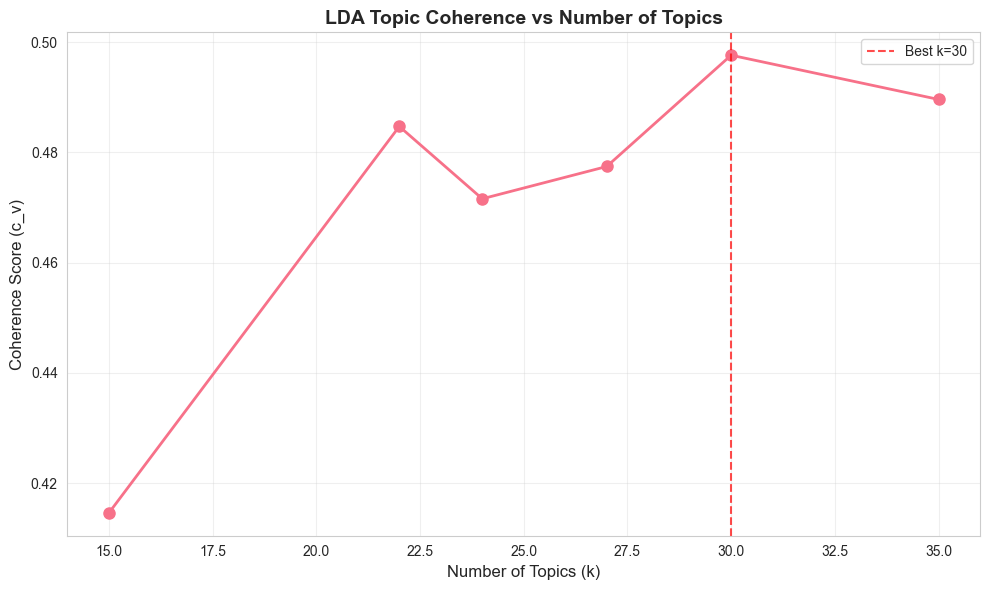

In [11]:
import multiprocessing
from gensim.models.coherencemodel import CoherenceModel
from gensim.models import LdaMulticore
import time

k_values = [15, 22, 24, 27, 30, 35]
coherence_scores = []
training_times = []

for k in k_values:
    print(f"Training LDA with k={k} topics...\n")
    
    start_time = time.time()
    
    lda_temp = LdaMulticore(
        corpus=corpus_2,
        id2word=dictionary_2,
        num_topics=k,
        passes=5,
        workers=multiprocessing.cpu_count() - 1,
        random_state=42,
        chunksize=2000
    )
    
    elapsed = time.time() - start_time
    training_times.append(elapsed)
    
    # Compute coherence score
    coherence_model = CoherenceModel(
        model=lda_temp,
        texts=df_clean_2['tags_tokens'],
        dictionary=dictionary_2,
        coherence='c_v'
    )
    coherence = coherence_model.get_coherence()
    coherence_scores.append(coherence)
    
    print(f"Coherence: {coherence:.4f} | Time: {elapsed/60:.1f} min")

# Results summary
results_df = pd.DataFrame({
    'k': k_values,
    'coherence': coherence_scores,
    'time_min': [t/60 for t in training_times]
})

print(f"\n{'='*50}")
print("Grid Search Results:")
print(f"{'='*50}")
print(results_df.to_string(index=False))

best_k_2 = results_df.loc[results_df['coherence'].idxmax(), 'k']
print(f"\nBest k: {int(best_k_2)} (Coherence: {results_df['coherence'].max():.4f})")

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(k_values, coherence_scores, marker='o', linewidth=2, markersize=8)
ax.axvline(best_k_2, color='red', linestyle='--', alpha=0.7, label=f'Best k={int(best_k_2)}')
ax.set_xlabel('Number of Topics (k)', fontsize=12)
ax.set_ylabel('Coherence Score (c_v)', fontsize=12)
ax.set_title('LDA Topic Coherence vs Number of Topics', fontsize=14, fontweight='bold')
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [12]:
print(f"\n{'='*20} Training Final Model (Tags) {'='*20}")
print(f"Training with k={int(best_k_2)} and passes=15...")
start_time = time.time()

lda_tags = LdaMulticore(
    corpus=corpus_2,
    id2word=dictionary_2,
    num_topics=int(best_k_2),
    passes=15,  # Higher passes for final quality
    workers=multiprocessing.cpu_count() - 1,
    random_state=42,
    per_word_topics=False,
    chunksize=2000
)

elapsed = time.time() - start_time
print(f"Final training complete in {elapsed/60:.1f} minutes")

# Display top words per topic
def print_top_words(model, n_top_words=15):
    for topic_idx in range(model.num_topics):
        top_words = [word for word, _ in model.show_topic(topic_idx, topn=n_top_words)]
        print(f"Topic #{topic_idx:02d}: {', '.join(top_words)}")

print(f"\nTop words for {int(best_k_2)} topics (Tag Method):")
print_top_words(lda_tags)


==================== Training Final Model (Tags) ====================
Training with k=30 and passes=15...
Final training complete in 5.1 minutes

Top words for 30 topics (Tag Method):
Topic #00: how_to, tutorial, diy, breaking_news, tips, easy, tricks, help, hindi, how-to, latest_news, howto, local_news, craft, crafts
Topic #01: london, uk, england, plane, airplane, flying, landing, dog_training, europe, youtube_editor, airport, healing, sermon, aircraft, aviation
Topic #02: beauty, makeup, fashion, health, fitness, style, cooking, workout, haul, hair, lifestyle, australia, training, bodybuilding, exercise
Topic #03: football, art, soccer, sports, highlights, rap, hockey, hip_hop, goals, nhl, goal, music, drawing, artist, painting
Topic #04: jesus, god, christian, bible, church, religion, christianity, love, faith, gospel, jesus_christ, israel, truth, holy, spirit
Topic #05: review, boxing, mma, ufc, omg, podcast, world_news, fight, headlines, sport, hoa, fighting, hangouts_on_air, ha

In [13]:
lda_path_2 = os.path.join(CACHED_RESUTLS_DIR, "lda_model_tags.model")
dict_path_2 = os.path.join(CACHED_RESUTLS_DIR, "dictionary_tags.dict")

print(f"\nSaving Tag-Based models to {CACHED_RESUTLS_DIR}...")
lda_tags.save(lda_path_2)
dictionary_2.save(dict_path_2)
print("Models (Tag-Based) saved successfully.")


Saving Tag-Based models to C:\Users\Jon\Desktop\ADA Project2\ada-2025-project-in5ight\data\cached_results...
Models (Tag-Based) saved successfully.


**Applying the topic model**: After selecting the tag representation and number of topics (30) based on coherence, we use the trained LDA model to assign topic distributions to all videos in the dataset.

In [14]:
import os
import re
from gensim.models import LdaMulticore
from gensim.corpora import Dictionary
from nltk.corpus import stopwords

# 1. Define Paths
lda_path_2 = os.path.join(CACHED_RESUTLS_DIR, "lda_model_tags.model")
dict_path_2 = os.path.join(CACHED_RESUTLS_DIR, "dictionary_tags.dict")

# 2. Load Models
print(f"Loading models from {CACHED_RESUTLS_DIR}...")
lda = LdaMulticore.load(lda_path_2)
dictionary = Dictionary.load(dict_path_2)
print(" Models loaded successfully.")

# 3. Define the Preprocessing Function for the Loop
# (Must match Method 1 logic exactly)
yt_stops = set(stopwords.words('english'))
yt_noise = {
        'video', 'videos', 'youtube', 'channel', 'subscribe', 'sub', 
        'like', 'comment', 'share', 'daily', 'weekly',
        'official', 'hd', 'hq', '4k', '1080p', '2009', '2010', '2011', '2012', '2013', 
        '2014', '2015', '2016', '2017', '2018', '2019',
        'best', 'top', 'funny', 'new', 'live', 'stream', 'full', 'episode'
}
yt_stops.update(yt_noise)

def clean_and_tokenize_tags_2(series):
    """
    Applies the Tag-Based (Comma) tokenization to a pandas Series.
    Used inside the inference loop.
    """
    def _tokenize(tag_str):
        if not isinstance(tag_str, str): 
            return []
        
        # 1. Split by comma (Tag-Based Logic)
        raw_tags = tag_str.lower().split(',')
        
        clean_tokens = []
        for t in raw_tags:
            # 2. Clean (allow spaces inside)
            t_clean = re.sub(r'[^a-z0-9\s_-]', '', t).strip()
            # 3. Collapse spaces
            t_clean = re.sub(r'\s+', ' ', t_clean)
            
            if len(t_clean) > 2 and not t_clean.isdigit() and t_clean not in yt_stops:
                # 4. Underscore join
                token = t_clean.replace(' ', '_')
                clean_tokens.append(token)
        return clean_tokens

    # Apply to the whole series/chunk
    return series.astype(str).apply(_tokenize)

print(" Tokenizer function 'clean_and_tokenize_tags' is ready.")

Loading models from C:\Users\Jon\Desktop\ADA Project2\ada-2025-project-in5ight\data\cached_results...
 Models loaded successfully.
 Tokenizer function 'clean_and_tokenize_tags' is ready.


In [ ]:
import glob
import re
import os
import shutil

import pandas as pd
import numpy as np
from tqdm import tqdm

OUTPUT_FOLDER = os.path.join(CACHED_RESUTLS_DIR, "rq2_video_topic")
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

# 1. robust Resume Logic
existing_files = glob.glob(os.path.join(OUTPUT_FOLDER, "chunk_*.parquet"))
if existing_files:
    # Find the max chunk ID
    last_chunk_id = max([int(re.search(r'chunk_(\d+)', f).group(1)) for f in existing_files if re.search(r'chunk_(\d+)', f)])
    
    print(f"Found last chunk: {last_chunk_id}. Re-processing this chunk to ensure data integrity...")
    
    # SAFETY STEP: Delete the last chunk. 
    # If it was corrupt (crash during write), this fixes it.
    # If it was fine, we just waste 1 minute re-doing it. Better safe than sorry.
    last_file_path = os.path.join(OUTPUT_FOLDER, f"chunk_{last_chunk_id}.parquet")
    if os.path.exists(last_file_path):
        os.remove(last_file_path)
        
    # Start counter from this ID (effectively re-doing it)
    chunk_counter = last_chunk_id
else:
    chunk_counter = 0

print(f"Starting/Resuming from chunk {chunk_counter}...")

# 2. Calculate rows to skip based on CLEAN chunks
# valid_chunks_count = chunk_counter (since we start counting from 0)
rows_to_skip = chunk_counter * 1_000_000

# 3. Main Loop
# Ensure your iterate_parquet_stream actually supports 'start_line' correctly!
for df_chunk in tqdm(iterate_parquet_stream(DATASET_TAGS, window_size=1_000_000, start_line=rows_to_skip)):
    
    # --- Preprocessing ---
    # Use the function we defined earlier (choose method1 or method2)
    texts = clean_and_tokenize_tags_2(df_chunk["tags"]) # <--- Make sure this function is defined/imported
    
    # --- Filter Empty ---
    valid_mask = texts.map(len) > 0
    if not valid_mask.any():
        print(f"Chunk {chunk_counter} was empty, skipping save...")
        chunk_counter += 1
        continue
    
    # --- Inference ---
    texts_valid = texts[valid_mask]
    corpus_batch = [dictionary.doc2bow(tokens) for tokens in texts_valid]
    
    gamma, _ = lda.inference(corpus_batch)
    dominant_topics = np.argmax(gamma, axis=1)
    
    df_batch_results = pd.DataFrame({
        'video_id': df_chunk.loc[valid_mask, "display_id"].values,
        'channel_id': df_chunk.loc[valid_mask, "channel_id"].values,
        'topic_id': dominant_topics
    })
    
    # --- Atomic Save (Optional but recommended) ---
    # Writing to a temp file and renaming is the safest way to avoid corruption
    filename = os.path.join(OUTPUT_FOLDER, f"chunk_{chunk_counter}.parquet")
    temp_filename = filename + ".tmp"
    
    df_batch_results.to_parquet(temp_filename, index=False)
    os.replace(temp_filename, filename) # Atomic move
    
    chunk_counter += 1

print(f"\nSaved chunks up to {chunk_counter} in {OUTPUT_FOLDER}/")

Starting/Resuming from chunk 0...


70it [5:10:04, 265.78s/it]

++ Final chunk: rows 72,393,216-72,924,794 | rows=531,578 | total=72,924,794

Saved chunks up to 70 in C:\Users\Jon\Desktop\ADA Project2\ada-2025-project-in5ight\data\cached_results\rq2_video_topic/


In [16]:
OUTPUT_FOLDER = CACHED_RESUTLS_DIR + "/rq2_video_topic"
print(f"Reading all chunks from: {OUTPUT_FOLDER}")

# Pandas automatically merges all parquet files in the folder
df_results = pd.read_parquet(OUTPUT_FOLDER)

print(f"Successfully loaded {len(df_results):,} rows.")
df_results.head()

Reading all chunks from: C:\Users\Jon\Desktop\ADA Project2\ada-2025-project-in5ight\data\cached_results/rq2_video_topic
Successfully loaded 65,601,549 rows.


,video_id,channel_id,topic_id
0,SBqSc91Hn9g,UCzWrhkg9eK5I8Bm3HfV-unA,0
1,UuugEl86ESY,UCzWrhkg9eK5I8Bm3HfV-unA,8
2,oB4c-yvnbjs,UCzWrhkg9eK5I8Bm3HfV-unA,0
3,ZaV-gTCMV8E,UCzWrhkg9eK5I8Bm3HfV-unA,0
4,cGvL7AvMfM0,UCzWrhkg9eK5I8Bm3HfV-unA,0


In [17]:
topic_dict = {}
for topic_idx in range(lda.num_topics):
    topic_dict[topic_idx] = [
        (word, round(float(prob), 3))
        for word, prob in lda.show_topic(topic_idx, topn=30)
    ]
    
for topic_id, pairs in topic_dict.items():
    print(f"\n=== Topic {topic_id} ===")
    for w, p in pairs:
        print(f"{w:20s} {p:.3f}")


=== Topic 0 ===
how_to               0.085
tutorial             0.068
diy                  0.055
breaking_news        0.033
tips                 0.031
easy                 0.019
tricks               0.018
help                 0.013
hindi                0.013
how-to               0.013
latest_news          0.011
howto                0.010
local_news           0.010
craft                0.009
crafts               0.009
do_it_yourself       0.009
how_to_make          0.009
spirituality         0.008
make                 0.008
spiritual            0.008
simple               0.008
repair               0.008
ideas                0.007
guide                0.007
entertainment_news   0.007
fix                  0.007
electronics          0.006
strategy             0.006
learn                0.006
homemade             0.006

=== Topic 1 ===
london               0.021
uk                   0.019
england              0.014
plane                0.013
airplane             0.013
flying               

**5.4 Topic labeling**: After fitting the LDA model, each topic is represented by its most probable keywords. We assign human-readable topic labels by prompting a large language model with the top-weighted keywords of each topic and requesting a concise category name that best summarizes the underlying content.

In [18]:
from src.models.topic_labeling import generate_topic_labels

df_labels = generate_topic_labels(topic_dict)

df_labels['keywords'] = df_labels['topic_id'].map(
    lambda tid: ", ".join(f"{w} ({p:.3f})" for w, p in topic_dict[tid])
)

print(df_labels.head())

Labeling 30 topics...


100%|██████████| 30/30 [00:26<00:00,  1.15it/s]

   topic_id           topic_label  \
0         0         DIY Tutorials   
1         1       London Aviation   
2         2      Beauty & Fitness   
3         3        Sports & Music   
4         4  Christianity & Faith   

                                            keywords  
0  how_to (0.085), tutorial (0.068), diy (0.055),...  
1  london (0.021), uk (0.019), england (0.014), p...  
2  beauty (0.031), makeup (0.024), fashion (0.024...  
3  football (0.050), art (0.032), soccer (0.031),...  
4  jesus (0.041), god (0.038), christian (0.031),...  


In [ ]:
# 1. Calculate Counts & Probability (Share of Voice)
df_counts = df_results.groupby(['channel_id', 'topic_id']).size().reset_index(name='video_count')
df_totals = df_results.groupby('channel_id').size().reset_index(name='total_videos')

df_final = df_counts.merge(df_totals, on='channel_id')
df_final['probability'] = df_final['video_count'] / df_final['total_videos']

# 2. Identify Dominant Topic (Voting)
# Sort by count desc, take the top 1 per channel
df_dominant = df_final.sort_values(['video_count', 'topic_id'], ascending=[False, True]) \
    .drop_duplicates('channel_id')[['channel_id', 'topic_id']] \
    .rename(columns={'topic_id': 'dominant_topic_id'})

# 3. Merge Everything
df_final = df_final.merge(df_dominant, on='channel_id', how='left')

# 4. Add Topic Labels
df_final = df_final.merge(
    df_labels, 
    left_on='topic_id', 
    right_on='topic_id', 
    how='left'
)

# 5. Final Column Selection
cols = [
    'channel_id', 
    'topic_id', 
    'topic_label', 
    'video_count', 
    'probability',       # Needed for Box Plots (Quartiles)
    'dominant_topic_id', # Needed for Voting/Categorization
    'keywords'
]
df_final = df_final[cols]

df_final.head()

,channel_id,topic_id,topic_label,video_count,probability,dominant_topic_id,keywords
0,UC--24Q3_ZQeFmgJE-Um5QZQ,29,Travel & Tourism,187,1.000000,29,"travel (0.044), adventure (0.018), tour (0.017..."
1,UC--2EbuIuBOGgGqPiJxi3rg,0,DIY Tutorials,9,0.169811,12,"how_to (0.085), tutorial (0.068), diy (0.055),..."
2,UC--2EbuIuBOGgGqPiJxi3rg,1,London Aviation,1,0.018868,12,"london (0.021), uk (0.019), england (0.014), p..."
3,UC--2EbuIuBOGgGqPiJxi3rg,6,Kids Tech Reviews,1,0.018868,12,"android (0.036), kids (0.033), unboxing (0.033..."
4,UC--2EbuIuBOGgGqPiJxi3rg,12,Aquarium & Fish Videos,32,0.603774,12,"fish (0.026), aquarium (0.021), water (0.013),..."


In [ ]:
# Load Outperformers (RQ1)
df_rq1 = pd.read_parquet(CACHED_RESUTLS_DIR + "/channels_outperformers.parquet")
# Merge with your final topics
# We use inner join to keep only channels where we have BOTH topic and performance data
df_analysis = df_final.merge(df_rq1, left_on='channel_id', right_on="channel", how='inner')

print(f"Analysis Dataset Ready: {len(df_analysis)} channels.")

Analysis Dataset Ready: 1870524 channels.


In [24]:
## Save df_analysis to cache
df_analysis.to_parquet(CACHED_RESUTLS_DIR + "/final_rq2_analysis.parquet")

In [11]:
df_analysis = pd.read_parquet(CACHED_RESUTLS_DIR + "/final_rq2_analysis.parquet")
df_analysis.head(5)

,channel_id,topic_id,topic_label,video_count,probability,dominant_topic_id,keywords,category_cc,join_date,channel,...,videos_per_day,avg_engagement_efficiency,total_views,total_duration,total_like_count,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed,is_outperformer
0,UC--24Q3_ZQeFmgJE-Um5QZQ,29,Travel & Tourism,187,1.000000,29,"travel (0.044), adventure (0.018), tour (0.017...",Travel & Events,2015-11-20,UC--24Q3_ZQeFmgJE-Um5QZQ,...,0.133612,0.048155,3291383.0,157394.0,64823.0,1544.0,10056.0,0.982468,189,False
1,UC--2EbuIuBOGgGqPiJxi3rg,0,DIY Tutorials,9,0.169811,12,"how_to (0.085), tutorial (0.068), diy (0.055),...",People & Blogs,2012-06-22,UC--2EbuIuBOGgGqPiJxi3rg,...,0.023108,0.028127,7999515.0,14639.0,38553.0,2383.0,2457.0,0.908158,60,False
2,UC--2EbuIuBOGgGqPiJxi3rg,1,London Aviation,1,0.018868,12,"london (0.021), uk (0.019), england (0.014), p...",People & Blogs,2012-06-22,UC--2EbuIuBOGgGqPiJxi3rg,...,0.023108,0.028127,7999515.0,14639.0,38553.0,2383.0,2457.0,0.908158,60,False
3,UC--2EbuIuBOGgGqPiJxi3rg,6,Kids Tech Reviews,1,0.018868,12,"android (0.036), kids (0.033), unboxing (0.033...",People & Blogs,2012-06-22,UC--2EbuIuBOGgGqPiJxi3rg,...,0.023108,0.028127,7999515.0,14639.0,38553.0,2383.0,2457.0,0.908158,60,False
4,UC--2EbuIuBOGgGqPiJxi3rg,12,Aquarium & Fish Videos,32,0.603774,12,"fish (0.026), aquarium (0.021), water (0.013),...",People & Blogs,2012-06-22,UC--2EbuIuBOGgGqPiJxi3rg,...,0.023108,0.028127,7999515.0,14639.0,38553.0,2383.0,2457.0,0.908158,60,False


In [12]:
# bypass the problem in RQ1, we should only analysis small-to-middle sized channels, filter out big channels (their is_outperformer are all false) 
df_analysis_rq2 = df_analysis[df_analysis["subscribers_cc"] < 100_000].copy()
print(f"Analysis Dataset for RQ2 Ready: {len(df_analysis_rq2)} rows.")


Analysis Dataset for RQ2 Ready: 1229483 rows.


In [12]:
import pandas as pd

# 1. Filter the dataframe to isolate the dominant topic row for each channel
# This assumes that for every channel, there is a row where topic_id == dominant_topic_id
df_dominant = df_analysis_rq2[df_analysis_rq2['topic_id'] == df_analysis_rq2['dominant_topic_id']].copy()

# 2. Select the specific columns and rename topic_label to dominant_topic_label
df_final = df_dominant[['channel_id', 'topic_label', 'category_cc']].rename(
    columns={'topic_label': 'dominant_topic_label'}
)

# 3. Optional: Drop duplicates to ensure exactly one row per channel_id
df_final = df_final.drop_duplicates(subset=['channel_id'])

# 4. Save the result to a parquet file
df_final.to_parquet(CACHED_RESUTLS_DIR + "/dominant_channel_topics.parquet", index=False)

print("Dataframe created and saved to 'dominant_channel_topics.parquet'.")

Dataframe created and saved to 'dominant_channel_topics.parquet'.


In [7]:
import pandas as pd
import re

# 1. Load your data
df = pd.read_parquet(CACHED_RESUTLS_DIR + "/final_rq2_analysis.parquet")
df = df[df["subscribers_cc"] < 100_000].copy()
# 2. Calculate the number of UNIQUE channels per dominant topic
# Even if a channel appears in multiple rows, nunique() ensures it is counted only once
channel_counts = df.groupby('dominant_topic_id')['channel_id'].nunique().reset_index(name='count_channel')

# 3. Extract the unique labels and keyword strings for each topic
# We take one representative row per topic_id
topic_info = df[['topic_id', 'topic_label', 'keywords']].drop_duplicates('topic_id')

# 4. Merge the counts into the topic information
df_summary = topic_info.merge(channel_counts, left_on='topic_id', right_on='dominant_topic_id')

# 5. Parse the 'keywords' string into a "long" format for Flourish
# This converts "word (0.05), word2 (0.04)" into individual rows
final_rows = []

for _, row in df_summary.iterrows():
    # Split keywords by the comma separator
    keyword_list = str(row['keywords']).split(', ')
    
    for item in keyword_list:
        # Regex to capture the word and the probability inside the parentheses
        match = re.search(r'(.+)\s\(([\d\.]+)\)', item)
        if match:
            word = match.group(1).strip()
            prob = float(match.group(2))
            
            final_rows.append({
                'topic_id': row['dominant_topic_id'],
                'topic_label': row['topic_label'],
                'keyword': word,
                'probability': prob,
                'count_channel': row['count_channel']
            })

# 6. Create DataFrame and Filter for Top 15 Keywords
df_flourish = pd.DataFrame(final_rows)

# Sort by topic and then by probability (highest first)
df_flourish = df_flourish.sort_values(['topic_id', 'probability'], ascending=[True, False])

# Keep only the top 15 rows for each topic_id
df_flourish = df_flourish.groupby('topic_id').head(15)

# 7. Save to CSV (Using / to avoid \f escape character issues)
output_path = CACHED_RESUTLS_DIR + '/flourish_topic_hierarchy.csv'
df_flourish.to_csv(output_path, index=False)

print(f"Success! Saved {len(df_flourish)} rows to 'flourish_topic_hierarchy.csv'.")

Success! Saved 450 rows to 'flourish_topic_hierarchy.csv'.


In [8]:
import pandas as pd
import re
import os

# 1. Load your data
df = pd.read_parquet(CACHED_RESUTLS_DIR + "/final_rq2_analysis.parquet")
df = df[df["subscribers_cc"] < 100_000].copy()
# 2. Calculate channel stats per topic (Total count and Proportion of Outperformers)
# Since one channel can have multiple rows but only one dominant_topic_id, 
# we drop duplicates to get a channel-level view first.
df_channel_unique = df.drop_duplicates('channel_id')

topic_stats = df_channel_unique.groupby('dominant_topic_id').agg(
    count_channel=('channel_id', 'count'),
    count_outperformer=('is_outperformer', 'sum')
).reset_index()

# Calculate the proportion
topic_stats['prop_outperformer'] = topic_stats['count_outperformer'] / topic_stats['count_channel']

# 3. Extract the unique labels and keyword strings for each topic
topic_info = df[['topic_id', 'topic_label', 'keywords']].drop_duplicates('topic_id')

# 4. Merge the stats into the topic information
df_summary = topic_info.merge(topic_stats, left_on='topic_id', right_on='dominant_topic_id')

# 5. Parse the 'keywords' string into a "long" format for Flourish
final_rows = []
for _, row in df_summary.iterrows():
    keyword_list = str(row['keywords']).split(', ')
    
    for item in keyword_list:
        match = re.search(r'(.+)\s\(([\d\.]+)\)', item)
        if match:
            word = match.group(1).strip()
            prob = float(match.group(2))
            
            final_rows.append({
                'topic_id': row['topic_id'],
                'topic_label': row['topic_label'],
                'keyword': word,
                'probability': prob,
                'count_channel': row['count_channel'],
                'prop_outperformer': row['prop_outperformer']  # New Column
            })

# 6. Create DataFrame and Filter for Top 15 Keywords
df_flourish = pd.DataFrame(final_rows)

# Sort by topic and then by probability (highest first)
df_flourish = df_flourish.sort_values(['topic_id', 'probability'], ascending=[True, False])

# Keep only the top 15 rows for each topic_id
df_flourish = df_flourish.groupby('topic_id').head(15)

# 7. Save to CSV
output_path = CACHED_RESUTLS_DIR + '/flourish_topic_hierarchy.csv'
df_flourish.to_csv(output_path, index=False)

print(f"Success! Saved {len(df_flourish)} rows to 'flourish_topic_hierarchy.csv'.")
print(f"Included 'prop_outperformer' column for visualization.")

Success! Saved 450 rows to 'flourish_topic_hierarchy.csv'.
Included 'prop_outperformer' column for visualization.


In [5]:
# --- Recreate df_labels ---
# 1. Select the two columns and drop duplicate rows
df_labels = df_analysis_rq2[['topic_id', 'topic_label']].drop_duplicates()

# 2. Sort by topic_id for clean presentation
df_labels = df_labels.sort_values('topic_id').reset_index(drop=True)

# 3. Create a dictionary map for sorting the final plot (optional, but helps with clarity)
topic_sort_map = df_labels.set_index('topic_label')['topic_id'].to_dict()

print(f"Reconstructed df_labels with {len(df_labels)} unique topics.")
# Display the labels to confirm
print(df_labels)

Reconstructed df_labels with 30 unique topics.
    topic_id                  topic_label
0          0                DIY Tutorials
1          1              London Aviation
2          2             Beauty & Fitness
3          3               Sports & Music
4          4         Christianity & Faith
5          5         MMA & Boxing Reviews
6          6            Kids Tech Reviews
7          7               Weather & Pets
8          8           Sports & Wrestling
9          9            Gaming & Gameplay
10        10  Skateboarding & Photography
11        11       Tech Reviews & Gadgets
12        12       Aquarium & Fish Videos
13        13                 Music Covers
14        14           US News & Politics
15        15           Cute Animal Videos
16        16         Car Racing & Reviews
17        17                 Comedy Vlogs
18        18    Korean TV & Space Culture
19        19           Food & School Life
20        20       Movie & Anime Trailers
21        21                T

In [4]:
# Filter to Single-Row-Per-Channel (Crucial for Statistical Tests)
# We select ONLY the row where the specific topic_id is the channel's overall dominant topic.
df_analysis_test = df_analysis_rq2[
    df_analysis_rq2['topic_id'] == df_analysis_rq2['dominant_topic_id']
].copy()

print(f"Filtered df_analysis_test (Test Ready): {len(df_analysis_test):,} channels.")

Filtered df_analysis_test (Test Ready): 91,805 channels.


In [10]:
df_analysis_test.columns

Index(['channel_id', 'topic_id', 'topic_label', 'video_count', 'probability',
       'dominant_topic_id', 'keywords', 'category_cc', 'join_date', 'channel',
       'name_cc', 'subscribers_cc', 'videos_cc', 'subscriber_rank_sb',
       'weights', 'channel_age_days', 'videos_per_day',
       'avg_engagement_efficiency', 'total_views', 'total_duration',
       'total_like_count', 'total_dislike_count', 'total_num_comms',
       'avg_video_like_ratio', 'video_count_processed', 'is_outperformer'],
      dtype='object')

In [7]:
# 1. Total number of rows in the filtered table
total_rows = len(df_analysis_test)

# 2. Number of unique channel IDs in the filtered table
unique_channels = df_analysis_test['channel_id'].nunique()

# 3. Check for consistency
is_single_row_per_channel = (total_rows == unique_channels)

print(f"Total rows in df_analysis_test: {total_rows:,}")
print(f"Unique channel IDs in df_analysis_test: {unique_channels:,}")
print("---")
print(f"Result: Is it one row per channel? **{is_single_row_per_channel}**")

# Optional: If the result is False, this code will show which channels have duplicates:
if not is_single_row_per_channel:
    print("\nChannels with duplicate rows found:")
    duplicate_channels = df_analysis_test['channel_id'].value_counts()
    print(duplicate_channels[duplicate_channels > 1].head())

Total rows in df_analysis_test: 91,805
Unique channel IDs in df_analysis_test: 91,805
---
Result: Is it one row per channel? **True**


RQ2.1 (Variation)

are content categories inherently different in performance (using Kruskal-Wallis)

H0​:All groups come from the same distribution

checks if the median avg_engagement_efficiency is significantly different across 30 topic groups


--- RQ2.1 Statistical Result (Kruskal-Wallis) ---
Kruskal-Wallis H-test P-value: 0.0000e+00
RESULT: Significant. Engagement baselines vary by topic.


C:\Users\Esabella D\AppData\Local\Temp\ipykernel_6412\4187389639.py:28: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




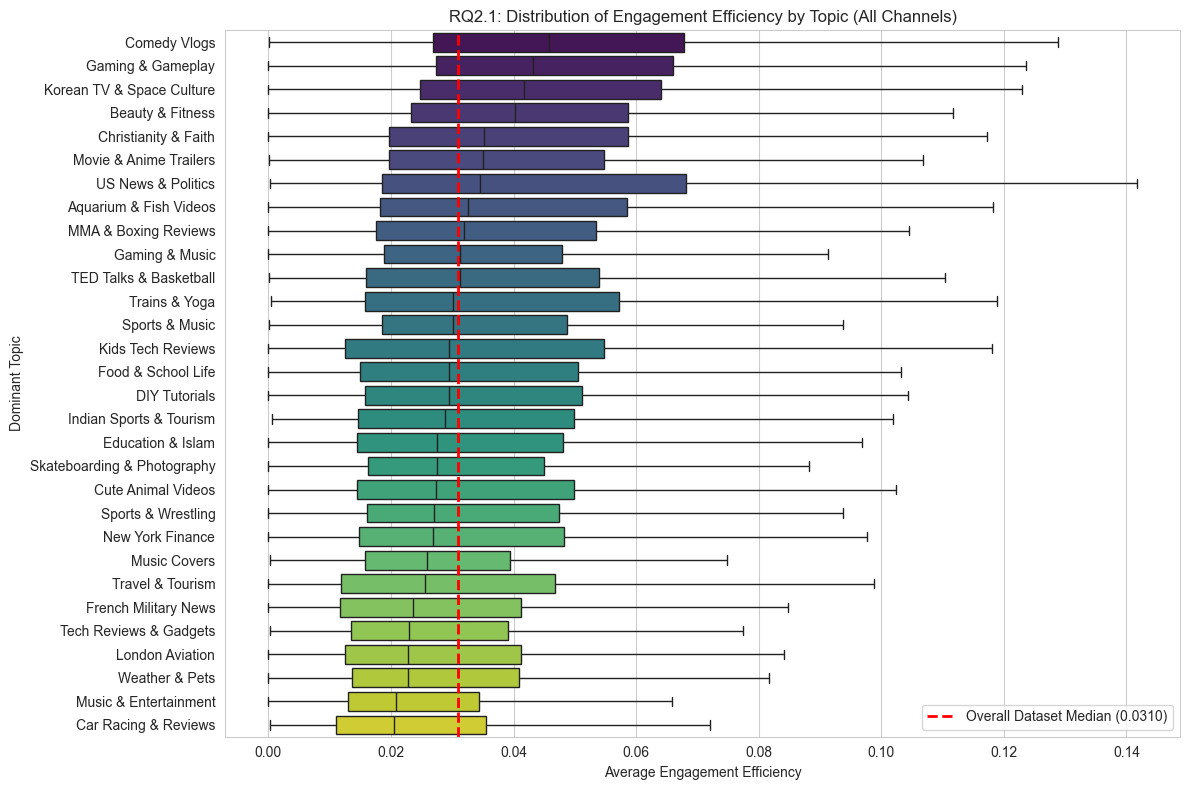

In [48]:
from scipy.stats import chi2_contingency, kruskal
# Group the efficiency scores by topic label
grouped_data = [
    group['avg_engagement_efficiency'].values
    for name, group in df_analysis_test.groupby('topic_label')
]

# Run the Kruskal-Wallis H-Test
h_kw, p_kw = kruskal(*grouped_data)

print("\n--- RQ2.1 Statistical Result (Kruskal-Wallis) ---")
print(f"Kruskal-Wallis H-test P-value: {p_kw:.4e}")

if p_kw < 0.05:
    print("RESULT: Significant. Engagement baselines vary by topic.")
else:
    print("RESULT: No difference. All topics have similar efficiency.")

# --- Plot ---
plt.figure(figsize=(12, 8))

# calculate the overall median (The "Overall Dataset Average")
overall_median = df_analysis_test['avg_engagement_efficiency'].median()

# Sort by median efficiency for a clean chart
order = df_analysis_test.groupby('topic_label')['avg_engagement_efficiency'].median().sort_values(ascending=False).index

sns.boxplot(
    data=df_analysis_test,
    y='topic_label',
    x='avg_engagement_efficiency',
    order=order,
    palette="viridis",
    showfliers=False # Hide extreme outliers for readability
)

# add a horizontal reference line (The "Overall Dataset Average")
plt.axvline(
    x=overall_median,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Overall Dataset Median ({overall_median:.4f})'
)

# Add Legend to show the average line
plt.legend()

plt.title('RQ2.1: Distribution of Engagement Efficiency by Topic (All Channels)')
plt.xlabel('Average Engagement Efficiency')
plt.ylabel('Dominant Topic')
plt.tight_layout()
plt.show()

RQ2.2 (Concentration): Are quiet outperformers concentrated in particular content categories?

In [7]:
# Chi-Square Test of Independence: 
# H0: the two variables is_outperformer and topic_label are independent
# Create the contingency table (counts of channels per topic per outperformer status)
contingency_table = pd.crosstab(
    df_analysis_test['topic_label'],
    df_analysis_test['is_outperformer']
)

# Run the Chi-Square Test
chi2, p_chi2, dof, expected = chi2_contingency(contingency_table)

print("\n--- RQ2.2 Statistical Result (Chi-Square) ---")
print(f"Chi-Square Test P-value: {p_chi2:.4e}")

if p_chi2 < 0.05:
    print("RESULT: Significant. Outperformers are concentrated in specific topics.")
else:
    print("RESULT: No concentration. Outperformers are randomly distributed.")


--- RQ2.2 Statistical Result (Chi-Square) ---
Chi-Square Test P-value: 1.8589e-129
RESULT: Significant. Outperformers are concentrated in specific topics.


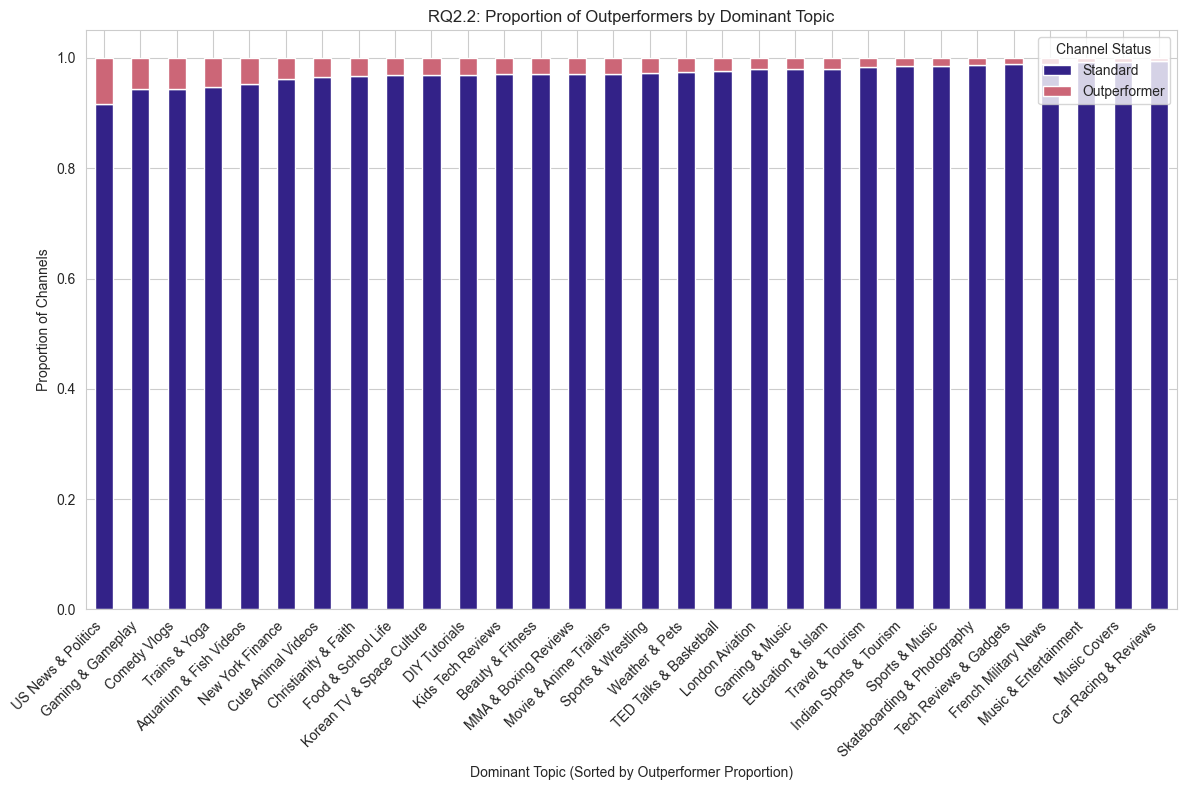

In [8]:
# Normalize the counts to show the proportion of Outperformers within each topic
topic_proportions = contingency_table.div(contingency_table.sum(axis=1), axis=0)
topic_proportions.rename(columns={True: 'Outperformer', False: 'Standard'}, inplace=True)

# Sort by the proportion of outperformers for visual clarity
sorted_proportions = topic_proportions.sort_values(by='Outperformer', ascending=False).index
topic_proportions_sorted = topic_proportions.loc[sorted_proportions]

plt.figure(figsize=(12, 8))
topic_proportions_sorted.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 8),
    color={'Outperformer': '#CC6677', 'Standard': "#332288"}, # Changed colors slightly for clarity
    ax=plt.gca() # Removed the erroneous 'order' parameter
)

plt.title('RQ2.2: Proportion of Outperformers by Dominant Topic')
plt.xlabel('Dominant Topic (Sorted by Outperformer Proportion)')
plt.ylabel('Proportion of Channels')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Channel Status', loc='upper right')
plt.tight_layout()
plt.show()

Top 5 Most Concentrated Topics (Highest Proportion of Outperformers):
US News & Politics, Gaming & Gameplay, Comedy Vlogs, Trains & Yoga, Aquarium & Fish Videos
Specializing in these areas gives a channel the highest chance of being an Outperformer.

RQ2.3 (Specialization): Compare the content strategy (Share of Voice) of outperformers.

Content specialization: If a channel's probability for Gaming is 0.70, it means that the channel is highly specialized in gaming.

RQ: if content specialization leads to better performance

Boxplot: For a given topic, do channels categorized as 'Outperformers' dedicate a significantly larger share of their content to it compared to non-outperformers channels?

Interpretation:

If the Green Box (Outperformer) is far to the right of the Red Box (Standard): This means outperformers, on average, dedicate a significantly higher proportion of their videos to this topic. Conclusion: Specialization in this topic is a necessary strategy for outperformance.

If the two boxes overlap significantly: This means the share of content dedicated to the topic does not strongly separate high-performers from low-performers. Conclusion: Success in this topic is likely driven by factors other than specialization (e.g., video quality, timing, star power).

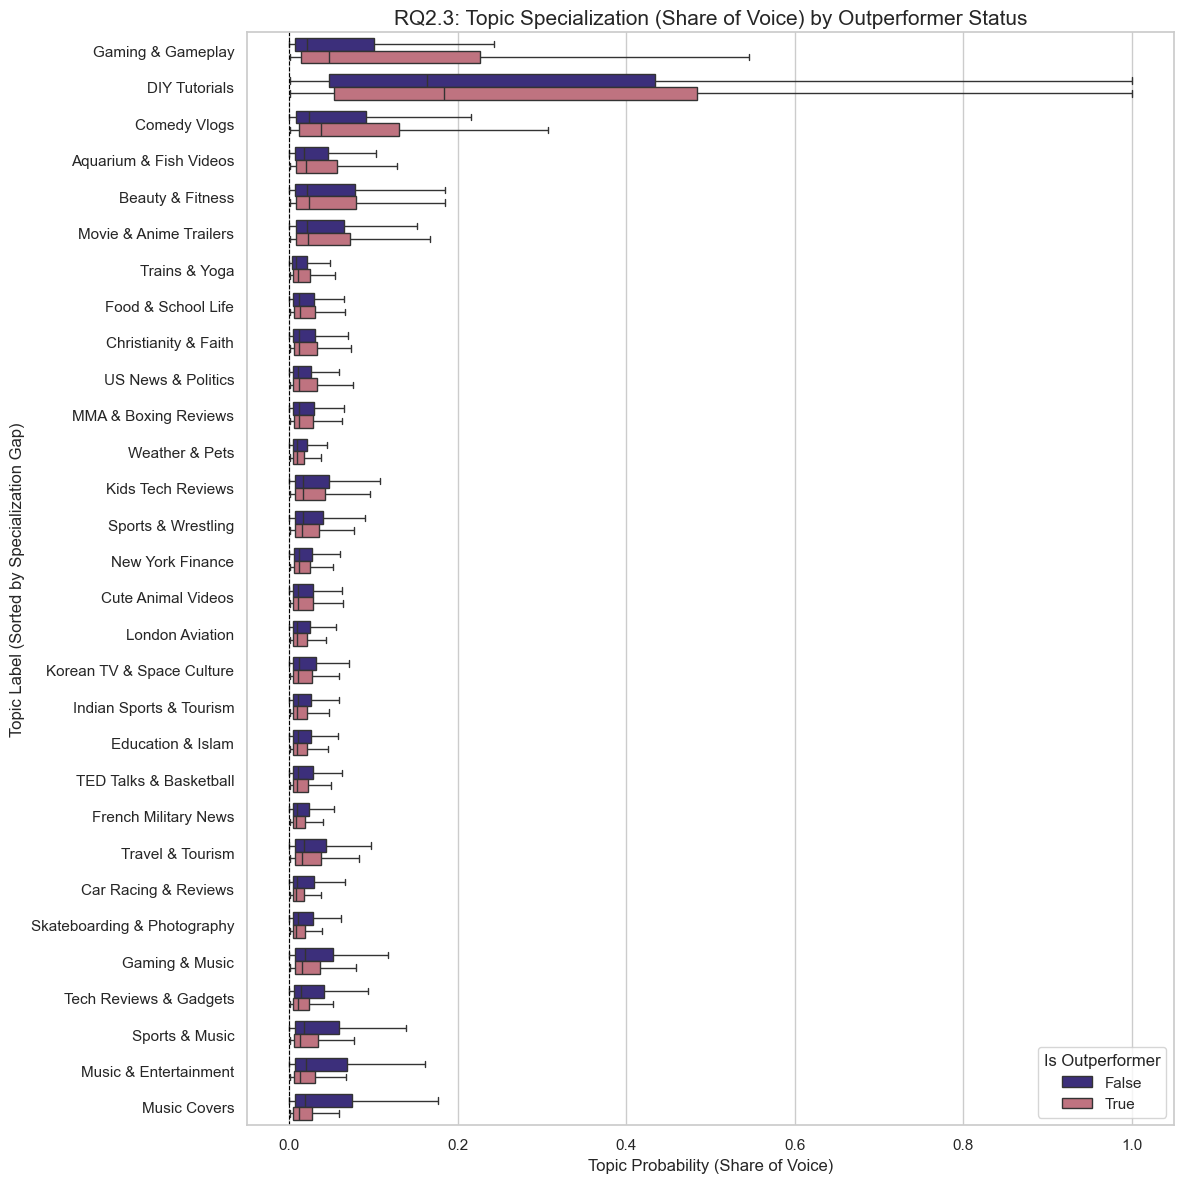

In [9]:
median_diff = df_analysis.groupby(['topic_label', 'is_outperformer'])['probability'].median().unstack()
median_diff['gap'] = median_diff[True] - median_diff[False]
sorted_order = median_diff.sort_values('gap', ascending=False).index.tolist()


plt.figure(figsize=(12, 12))
sns.set_theme(style="whitegrid")

sns.boxplot(
    data=df_analysis,  
    y='topic_label',
    x='probability',
    hue='is_outperformer',
    order=sorted_order,
    palette={True: "#CC6677", False: "#332288"},
    showfliers=False,
    width=0.7
)

plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.title('RQ2.3: Topic Specialization (Share of Voice) by Outperformer Status', fontsize=15)
plt.xlabel('Topic Probability (Share of Voice)')
plt.ylabel('Topic Label (Sorted by Specialization Gap)')
plt.legend(title='Is Outperformer', loc='lower right')
plt.tight_layout()
plt.show()

RQ2.4: Are outperformers usually more topic diverse?

In [8]:
from scipy.stats import mannwhitneyu
# --- 1. Calculate Shannon Entropy (Diversity) for each Channel ---

# Calculate p_i * ln(p_i) for each topic row
# Note: probability is 0 for topics a channel doesn't touch, p*ln(p) is defined as 0 in this case.
df_analysis['p_ln_p'] = df_analysis['probability'] * np.log(df_analysis['probability'].replace(0, 1))

# Group by channel and sum to get the negative Entropy (-H)
channel_entropy = df_analysis.groupby(['channel_id', 'is_outperformer'])['p_ln_p'].sum().reset_index()

# Calculate H: H = - sum(p*ln(p))
channel_entropy['diversity_entropy'] = -channel_entropy['p_ln_p']

# --- 2. Prepare Groups for Mann-Whitney U Test ---
group_outperformers = channel_entropy[channel_entropy['is_outperformer'] == True]['diversity_entropy']
group_standard = channel_entropy[channel_entropy['is_outperformer'] == False]['diversity_entropy']

# --- 3. Run Mann-Whitney U Test ---
u_stat, p_diversity = mannwhitneyu(group_outperformers, group_standard, alternative='two-sided')

print("\n--- Topic Diversity Analysis (Mann-Whitney U Test) ---")
print(f"P-value for Diversity Difference: {p_diversity:.4e}")

# --- 4. Conclusion ---
if p_diversity < 0.05:
    # Check medians to see who is more diverse
    median_outperformer = group_outperformers.median()
    median_standard = group_standard.median()

    if median_outperformer > median_standard:
        conclusion = "Outperformers are significantly MORE diverse (higher median Entropy)."
    else:
        conclusion = "Outperformers are significantly LESS diverse (lower median Entropy)."

    print(f"RESULT: Significant. {conclusion}")
    print(f"Median Entropy (Outperformer): {median_outperformer:.4f}")
    print(f"Median Entropy (Standard): {median_standard:.4f}")
else:
    print("RESULT: No significant difference in topic diversity between groups.")


--- Topic Diversity Analysis (Mann-Whitney U Test) ---
P-value for Diversity Difference: 9.6553e-02
RESULT: No significant difference in topic diversity between groups.


# Visualizations for data story

In [13]:
df_analysis_test.head(2)

,channel_id,topic_id,topic_label,video_count,probability,dominant_topic_id,keywords,category_cc,join_date,channel,...,videos_per_day,avg_engagement_efficiency,total_views,total_duration,total_like_count,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed,is_outperformer
0,UC--24Q3_ZQeFmgJE-Um5QZQ,29,Travel & Tourism,187,1.000000,29,"travel (0.044), adventure (0.018), tour (0.017...",Travel & Events,2015-11-20,UC--24Q3_ZQeFmgJE-Um5QZQ,...,0.133612,0.048155,3291383.0,157394.0,64823.0,1544.0,10056.0,0.982468,189,False
4,UC--2EbuIuBOGgGqPiJxi3rg,12,Aquarium & Fish Videos,32,0.603774,12,"fish (0.026), aquarium (0.021), water (0.013),...",People & Blogs,2012-06-22,UC--2EbuIuBOGgGqPiJxi3rg,...,0.023108,0.028127,7999515.0,14639.0,38553.0,2383.0,2457.0,0.908158,60,False


In [5]:
import plotly.express as px
import plotly.graph_objects as go

# 1. Prepare the data (Ensure topics are sorted by median efficiency)
df_sorted = df_analysis_test.copy()
topic_order = df_sorted.groupby('topic_label')['avg_engagement_efficiency'].median().sort_values(ascending=False).index

# 2. Calculate the Overall Median for the reference line
overall_median = df_sorted['avg_engagement_efficiency'].median()

# 3. Create the Interactive Box Plot
fig = px.box(
    df_sorted, 
    y="topic_label", 
    x="avg_engagement_efficiency",
    orientation='h',
    category_orders={"topic_label": topic_order},
    color="topic_label", # This gives each community a unique aesthetic color
    color_discrete_sequence=px.colors.qualitative.Prism, 
    points=False, # Hides outliers for a cleaner look
    title="Community Engagement Efficiency: Finding the High-Yield Clusters",
    labels={"avg_engagement_efficiency": "Efficiency Ratio", "topic_label": "Micro-Community"}
)

# 4. Add the "Overall Average" dashed line
fig.add_vline(
    x=overall_median, 
    line_dash="dash", 
    line_color="red", 
    annotation_text=f"Platform Average ({overall_median:.3f})", 
    annotation_position="top right"
)

# 5. Enhance Hover Information (This is where you show keywords!)
# Note: You'll need a dictionary mapping topic_label to its top keywords from your LDA results
fig.update_traces(
    hovertemplate="<b>Community:</b> %{y}<br><b>Median Efficiency:</b> %{x:.4f}<br><extra></extra>"
)

# 6. Aesthetic Styling
fig.update_layout(
    showlegend=False,
    height=800,
    template="plotly_white",
    xaxis_title="Return on Attention (Likes+Comments+Dislikes / Views)",
    yaxis_title="",
    font=dict(family="Arial", size=12)
)

fig.show()

In [17]:
import plotly.express as px
import plotly.graph_objects as go
from scipy.stats import chi2_contingency, kruskal

df_keywords = pd.read_csv(CACHED_RESUTLS_DIR + "/flourish_topic_hierarchy.csv")

# Expect columns like in your screenshot:
# topic_id, topic_label, keyword, probability, count_channel, prop_outperformer

# ------------------------------------------------------------
# 1) Build "top 3 keywords" string per topic_label from df_keywords
# ------------------------------------------------------------
TOP_N = 3

df_kw_top = (
    df_keywords
    .sort_values(["topic_label", "probability"], ascending=[True, False])
    .groupby("topic_label", as_index=False)
    .agg({
        "keyword": lambda s: ", ".join(s.head(TOP_N)),
        "count_channel": "first",        # same within a topic_label in your file
        "prop_outperformer": "first"     # same within a topic_label in your file
    })
    .rename(columns={"keyword": "clean_keywords"})
)

# Optional: if you prefer nicer display (e.g., "how_to" -> "how to")
df_kw_top["clean_keywords"] = df_kw_top["clean_keywords"].str.replace("_", " ", regex=False)

# ------------------------------------------------------------
# 2) Aggregate efficiency stats from df_analysis_test (same as before, minus keywords)
# ------------------------------------------------------------
df_agg = df_analysis_test[df_analysis_test["topic_id"] == df_analysis_test["dominant_topic_id"]].copy()

# Perform the Kruskal-Wallis Test
grouped_data = [group['avg_engagement_efficiency'].values for name, group in df_agg.groupby('topic_label')]
h_kw, p_kw = kruskal(*grouped_data)

df_plot = (
    df_agg.groupby("topic_label", as_index=False)
    .agg({
        "avg_engagement_efficiency": "median",
        "channel_id": "count",
        "subscribers_cc": "sum",
    })
)

# ------------------------------------------------------------
# 3) Merge in keywords + (optional) topic-level stats from the csv
# ------------------------------------------------------------
df_plot = df_plot.merge(df_kw_top, on="topic_label", how="left")

# If some topics are missing from df_keywords, avoid NaNs in hover
df_plot["clean_keywords"] = df_plot["clean_keywords"].fillna("(no keywords)")
df_plot["prop_outperformer"] = df_plot["prop_outperformer"].fillna(float("nan"))
df_plot["count_channel"] = df_plot["count_channel"].fillna(df_plot["channel_id"])

df_plot = df_plot.sort_values("avg_engagement_efficiency")

# 1) Sort by median engagement efficiency (descending)
order_by_median = (
    df_plot.sort_values("avg_engagement_efficiency", ascending=False)["topic_label"]
    .tolist()
)

# 2) Sort by proportion of outperformers (descending)
order_by_outperf = (
    df_plot.sort_values("prop_outperformer", ascending=False)["topic_label"]
    .tolist()
)

# Keep df_plot in one "default" order for the initial render (choose median)
df_plot = df_plot.set_index("topic_label").loc[order_by_median].reset_index()

# ------------------------------------------------------------
# 4) Plot (same structure, updated hover fields)
# ------------------------------------------------------------
overall_median = df_agg["avg_engagement_efficiency"].median()
fig = go.Figure()
# Statistical Annotation Text
ann_text = (
    f"H0: All groups come from the same distribution (median efficiency is the same across all 30 topics).<br>"
    f"Kruskal-Wallis H-Test: p = {p_kw:.4e}"
    f"{'-> reject H0, performance is inherently different across categories.' if p_kw < 0.05 else 'fail to reject H₀.'}<br>"
)
fig.add_vline(
    x=overall_median,
    line_width=2,
    line_dash="dash",
    line_color="red",
    annotation_text=f"Overall Median = {overall_median:.4f}",
    annotation_position="bottom right",
    annotation_font=dict(
        color="red",
        size=12,
    ),
)

# customdata columns order matters for hovertemplate indexing
custom_cols = ["clean_keywords", "channel_id", "prop_outperformer"]
customdata = df_plot[custom_cols].to_numpy()

fig.add_trace(go.Bar(
    x=df_plot["avg_engagement_efficiency"],
    y=df_plot["topic_label"],
    width=0.6,
    orientation="h",
    marker=dict(
        color=df_plot["avg_engagement_efficiency"],
        colorscale="Viridis",
        line=dict(color="rgba(255, 255, 255, 0.5)", width=1),
    ),
    customdata=customdata,
    hovertemplate=(
        "<b>Community: %{y}</b><br>"
        "Median Efficiency: <b>%{x:.4f}</b><br>"
        "Channels in Topic: %{customdata[1]}<br>"
        "Top Keywords: <i>%{customdata[0]}</i><br>"
        "Outperformer Proportion: <b>%{customdata[2]:.2%}</b>"
        "<extra></extra>"
    ),
))

# 1. First, update the layout without touching annotations
fig.update_layout(
    title="<b>Engagement Efficiency by Topic Community</b>",
    xaxis_title="Median Engagement Efficiency",
    template="plotly_white",
    height=800,
    margin=dict(l=220, r=50, t=40, b=150), # Increased bottom margin
    xaxis_rangeslider_visible=False,
    yaxis=dict(autorange="reversed") # Keeps high values at top if sorted descending
)

# 2. Append the statistical text to the existing annotations (the vline label)
fig.add_annotation(
    text=ann_text,
    x=-0.1, y=-0.1,      # Positioned below the axis
    xref="paper", yref="paper",
    showarrow=False, align="left",
    xanchor="left", yanchor="top",
    font=dict(size=12, color="black")
)

# 3. Add your updatemenus (dropdown)
fig.update_layout(
    updatemenus=[
        dict(
            buttons=[
                dict(label="Sort: Median Efficiency", method="relayout",
                     args=[{"yaxis.categoryarray": order_by_median}]),
                dict(label="Sort: Outperformer Proportion", method="relayout",
                     args=[{"yaxis.categoryarray": order_by_outperf}]),
            ],
            direction="down",
            showactive=True,
            x=1.0, xanchor="right",
            y=1.06, yanchor="top",
        )
    ]
)

from pathlib import Path

OUT_HTML = Path(CACHED_RESUTLS_DIR, "rq2_efficiency_by_topic.html")
OUT_HTML.parent.mkdir(parents=True, exist_ok=True)

fig.write_html(str(OUT_HTML), include_plotlyjs="cdn", full_html=True)
print("Wrote:", OUT_HTML.resolve())

fig.show()

Wrote: E:\epflADA\ada-project\ada-2025-project-in5ight\data\cached_results\rq2_efficiency_by_topic.html


In [94]:
df_keywords = pd.read_csv(CACHED_RESUTLS_DIR + "/flourish_topic_hierarchy.csv")

# Expect columns like in your screenshot:
# topic_id, topic_label, keyword, probability, count_channel, prop_outperformer

# ------------------------------------------------------------
# 1) Build "top 3 keywords" string per topic_label from df_keywords
# ------------------------------------------------------------
TOP_N = 3

df_kw_top = (
    df_keywords
    .sort_values(["topic_label", "probability"], ascending=[True, False])
    .groupby("topic_label", as_index=False)
    .agg({
        "keyword": lambda s: ", ".join(s.head(TOP_N)),
        "count_channel": "first",        # same within a topic_label in your file
        "prop_outperformer": "first"     # same within a topic_label in your file
    })
    .rename(columns={"keyword": "clean_keywords"})
)

# Optional: if you prefer nicer display (e.g., "how_to" -> "how to")
df_kw_top["clean_keywords"] = df_kw_top["clean_keywords"].str.replace("_", " ", regex=False)

# ------------------------------------------------------------
# 2) Aggregate efficiency stats from df_analysis_test (same as before, minus keywords)
# ------------------------------------------------------------
df_agg = df_analysis_test[df_analysis_test["topic_id"] == df_analysis_test["dominant_topic_id"]].copy()

df_plot = (
    df_agg.groupby("topic_label", as_index=False)
    .agg({
        "avg_engagement_efficiency": "median",
        "channel_id": "count",
        "subscribers_cc": "sum",
    })
)

# ------------------------------------------------------------
# 3) Merge in keywords + (optional) topic-level stats from the csv
# ------------------------------------------------------------
df_plot = df_plot.merge(df_kw_top, on="topic_label", how="left")

# If some topics are missing from df_keywords, avoid NaNs in hover
df_plot["clean_keywords"] = df_plot["clean_keywords"].fillna("(no keywords)")
df_plot["prop_outperformer"] = df_plot["prop_outperformer"].fillna(float("nan"))
df_plot["count_channel"] = df_plot["count_channel"].fillna(df_plot["channel_id"])

df_plot = df_plot.sort_values("avg_engagement_efficiency")

# 1) Sort by median engagement efficiency (descending)
order_by_median = (
    df_plot.sort_values("avg_engagement_efficiency")["topic_label"]
    .tolist()
)

# 2) Sort by proportion of outperformers (descending)
order_by_outperf = (
    df_plot.sort_values("prop_outperformer")["topic_label"]
    .tolist()
)

# Keep df_plot in one "default" order for the initial render (choose median)
df_plot = df_plot.set_index("topic_label").loc[order_by_median].reset_index()

# ------------------------------------------------------------
# 4) Plot (same structure, updated hover fields)
# ------------------------------------------------------------
overall_median = df_agg["avg_engagement_efficiency"].median()
fig = go.Figure()
fig.add_vline(
    x=overall_median,
    line_width=2,
    line_dash="dash",
    line_color="red",
    annotation_text=f"Overall Median = {overall_median:.4f}",
    annotation_position="bottom right",
    annotation_font=dict(
        color="red",
        size=12,
    ),
)

# customdata columns order matters for hovertemplate indexing
custom_cols = ["clean_keywords", "channel_id", "prop_outperformer"]
customdata = df_plot[custom_cols].to_numpy()

fig.add_trace(go.Bar(
    x=df_plot["avg_engagement_efficiency"],
    y=df_plot["topic_label"],
    orientation="h",
    marker=dict(
        color=df_plot["avg_engagement_efficiency"],
        colorscale="Viridis",
        line=dict(color="rgba(255, 255, 255, 0.5)", width=1),
    ),
    customdata=customdata,
    hovertemplate=(
        "<b>Community: %{y}</b><br>"
        "Median Efficiency: <b>%{x:.4f}</b><br>"
        "Channels in Topic: %{customdata[1]}<br>"
        "Top Keywords: <i>%{customdata[0]}</i><br>"
        "Outperformer Proportion: <b>%{customdata[2]:.2%}</b>"
        "<extra></extra>"
    ),
))

fig.update_layout(
    updatemenus=[
        dict(
            buttons=[
                dict(
                    label="Sort: Median Efficiency",
                    method="relayout",
                    args=[{
                        "yaxis.categoryorder": "array",
                        "yaxis.categoryarray": order_by_median
                    }],
                ),
                dict(
                    label="Sort: Outperformer Proportion",
                    method="relayout",
                    args=[{
                        "yaxis.categoryorder": "array",
                        "yaxis.categoryarray": order_by_outperf
                    }],
                ),
            ],
            direction="down",
            showactive=True,
            x=1.00,
            y=1.10,
            xanchor="left",
            yanchor="top",
        )
    ],
    title="<b>Engagement Efficiency by Topic Community</b>",
    xaxis_title="Median Engagement Efficiency",
    template="plotly_white",
    height=800,
    xaxis_rangeslider_visible=False,
    margin=dict(l=200),
)

fig.show()

In [46]:
import plotly.express as px
import numpy as np
import json

# Values used for coloring
vals = df_plot["avg_engagement_efficiency"].to_numpy(dtype=float)
vmin, vmax = float(np.nanmin(vals)), float(np.nanmax(vals))

def viridis_color_for_value(v: float) -> str:
    t = 0.5 if vmax == vmin else (v - vmin) / (vmax - vmin)
    return px.colors.sample_colorscale("Viridis", [t])[0]

# Build topic → color mapping
df_topic_colors = df_plot[["topic_label", "avg_engagement_efficiency"]].copy()
df_topic_colors["color"] = df_topic_colors["avg_engagement_efficiency"].apply(
    viridis_color_for_value
)

# Keep only what is needed and sort (optional but nice)
topic_color_json = (
    df_topic_colors
    .rename(columns={"topic_label": "topic"})
    [["topic", "color"]]
    .sort_values("topic")
    .to_dict(orient="records")
)

# Output JSON
json_str = json.dumps(topic_color_json, indent=2)
print(json_str)


[
  {
    "topic": "Aquarium & Fish Videos",
    "color": "rgb(36, 139, 140)"
  },
  {
    "topic": "Beauty & Fitness",
    "color": "rgb(112, 206, 87)"
  },
  {
    "topic": "Car Racing & Reviews",
    "color": "rgb(68, 1, 84)"
  },
  {
    "topic": "Christianity & Faith",
    "color": "rgb(36, 164, 133)"
  },
  {
    "topic": "Comedy Vlogs",
    "color": "rgb(253, 231, 37)"
  },
  {
    "topic": "Cute Animal Videos",
    "color": "rgb(56, 88, 139)"
  },
  {
    "topic": "DIY Tutorials",
    "color": "rgb(47, 109, 142)"
  },
  {
    "topic": "Education & Islam",
    "color": "rgb(55, 89, 140)"
  },
  {
    "topic": "Food & School Life",
    "color": "rgb(47, 109, 142)"
  },
  {
    "topic": "French Military News",
    "color": "rgb(71, 44, 122)"
  },
  {
    "topic": "Gaming & Gameplay",
    "color": "rgb(187, 223, 42)"
  },
  {
    "topic": "Gaming & Music",
    "color": "rgb(39, 127, 142)"
  },
  {
    "topic": "Indian Sports & Tourism",
    "color": "rgb(49, 104, 142)"
  },
  {
   

In [ ]:
TOPIC_COLOR_LIST = [
    {"topic": "DIY Tutorials", "color": "#CC6677"},
    {"topic": "London Aviation", "color": "#AA4499"},
    {"topic": "Beauty & Fitness", "color": "#DDCC77"},
    {"topic": "Sports & Music", "color": "#882255"},
    {"topic": "Christianity & Faith", "color": "#117733"},
    {"topic": "MMA & Boxing Reviews", "color": "#999933"},
    {"topic": "Kids Tech Reviews", "color": "#CC6677"},
    {"topic": "Weather & Pets", "color": "#DDDDDD"},
    {"topic": "Sports & Wrestling", "color": "#44AA99"},
    {"topic": "Gaming & Gameplay", "color": "#332288"},
    {"topic": "Skateboarding & Photography", "color": "#DDDDDD"},
    {"topic": "Tech Reviews & Gadgets", "color": "#88CCEE"},
    {"topic": "Aquarium & Fish Videos", "color": "#DDDDDD"},
    {"topic": "Music Covers", "color": "#88CCEE"},
    {"topic": "US News & Politics", "color": "#117733"},
    {"topic": "Cute Animal Videos", "color": "#DDCC77"},
    {"topic": "Car Racing & Reviews", "color": "#332288"},
    {"topic": "Comedy Vlogs", "color": "#117733"},
    {"topic": "Korean TV & Space Culture", "color": "#882255"},
    {"topic": "Food & School Life", "color": "#44AA99"},
    {"topic": "Movie & Anime Trailers", "color": "#44AA99"},
    {"topic": "Trains & Yoga", "color": "#999933"},
    {"topic": "TED Talks & Basketball", "color": "#CC6677"},
    {"topic": "New York Finance", "color": "#332288"},
    {"topic": "Music & Entertainment", "color": "#999933"},
    {"topic": "Indian Sports & Tourism", "color": "#88CCEE"},
    {"topic": "Education & Islam", "color": "#882255"},
    {"topic": "French Military News", "color": "#AA4499"},
    {"topic": "Gaming & Music", "color": "#AA4499"},
    {"topic": "Travel & Tourism", "color": "#DDCC77"},
]

TOPIC_TO_COLOR = {d["topic"]: d["color"] for d in TOPIC_COLOR_LIST}
df_keywords = pd.read_csv(CACHED_RESUTLS_DIR + "/flourish_topic_hierarchy.csv")

# Expect columns like in your screenshot:
# topic_id, topic_label, keyword, probability, count_channel, prop_outperformer

# ------------------------------------------------------------
# 1) Build "top 3 keywords" string per topic_label from df_keywords
# ------------------------------------------------------------
TOP_N = 3

df_kw_top = (
    df_keywords
    .sort_values(["topic_label", "probability"], ascending=[True, False])
    .groupby("topic_label", as_index=False)
    .agg({
        "keyword": lambda s: ", ".join(s.head(TOP_N)),
        "count_channel": "first",        # same within a topic_label in your file
        "prop_outperformer": "first"     # same within a topic_label in your file
    })
    .rename(columns={"keyword": "clean_keywords"})
)

# Optional: if you prefer nicer display (e.g., "how_to" -> "how to")
df_kw_top["clean_keywords"] = df_kw_top["clean_keywords"].str.replace("_", " ", regex=False)

# ------------------------------------------------------------
# 2) Aggregate efficiency stats from df_analysis_test (same as before, minus keywords)
# ------------------------------------------------------------
df_agg = df_analysis_test[df_analysis_test["topic_id"] == df_analysis_test["dominant_topic_id"]].copy()

df_plot = (
    df_agg.groupby("topic_label", as_index=False)
    .agg({
        "avg_engagement_efficiency": "median",
        "channel_id": "count",
        "subscribers_cc": "sum",
    })
)

# ------------------------------------------------------------
# 3) Merge in keywords + (optional) topic-level stats from the csv
# ------------------------------------------------------------
df_plot = df_plot.merge(df_kw_top, on="topic_label", how="left")

# If some topics are missing from df_keywords, avoid NaNs in hover
df_plot["clean_keywords"] = df_plot["clean_keywords"].fillna("(no keywords)")
df_plot["prop_outperformer"] = df_plot["prop_outperformer"].fillna(float("nan"))
df_plot["count_channel"] = df_plot["count_channel"].fillna(df_plot["channel_id"])

df_plot = df_plot.sort_values("avg_engagement_efficiency")

# 1) Sort by median engagement efficiency (descending)
order_by_median = (
    df_plot.sort_values("avg_engagement_efficiency")["topic_label"]
    .tolist()
)

# 2) Sort by proportion of outperformers (descending)
order_by_outperf = (
    df_plot.sort_values("prop_outperformer")["topic_label"]
    .tolist()
)

# Keep df_plot in one "default" order for the initial render (choose median)
df_plot = df_plot.set_index("topic_label").loc[order_by_median].reset_index()

# Assign colors by topic (fallback to light gray if missing)
df_plot["topic_color"] = df_plot["topic_label"].map(TOPIC_TO_COLOR).fillna("#CCCCCC")

# ------------------------------------------------------------
# 4) Plot (same structure, updated hover fields)
# ------------------------------------------------------------
overall_median = df_agg["avg_engagement_efficiency"].median()
fig = go.Figure()
fig.add_vline(
    x=overall_median,
    line_width=2,
    line_dash="dash",
    line_color="red",
    annotation_text=f"Overall Median = {overall_median:.4f}",
    annotation_position="bottom right",
    annotation_font=dict(
        color="red",
        size=12,
    ),
)

# customdata columns order matters for hovertemplate indexing
custom_cols = ["clean_keywords", "channel_id", "prop_outperformer"]
customdata = df_plot[custom_cols].to_numpy()

fig.add_trace(go.Bar(
    x=df_plot["avg_engagement_efficiency"],
    y=df_plot["topic_label"],
    orientation="h",
    marker=dict(
        color=df_plot["topic_color"],
        line=dict(color="rgba(255, 255, 255, 0.5)", width=1),
    ),
    customdata=customdata,
    hovertemplate=(
        "<b>Community: %{y}</b><br>"
        "Median Efficiency: <b>%{x:.4f}</b><br>"
        "Channels in Topic: %{customdata[1]}<br>"
        "Top Keywords: <i>%{customdata[0]}</i><br>"
        "Outperformer Proportion: <b>%{customdata[2]:.2%}</b>"
        "<extra></extra>"
    ),
))

fig.update_layout(
    updatemenus=[
        dict(
            buttons=[
                dict(
                    label="Sort: Median Efficiency",
                    method="relayout",
                    args=[{
                        "yaxis.categoryorder": "array",
                        "yaxis.categoryarray": order_by_median
                    }],
                ),
                dict(
                    label="Sort: Outperformer Proportion",
                    method="relayout",
                    args=[{
                        "yaxis.categoryorder": "array",
                        "yaxis.categoryarray": order_by_outperf
                    }],
                ),
            ],
            direction="down",
            showactive=True,
            x=1.00,
            y=1.10,
            xanchor="left",
            yanchor="top",
        )
    ],
    title="<b>Engagement Efficiency by Topic Community</b>",
    xaxis_title="Median Engagement Efficiency",
    template="plotly_white",
    height=800,
    xaxis_rangeslider_visible=False,
    margin=dict(l=200),
)

fig.show()

In [34]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
contingency_table = pd.crosstab(
    df_analysis_test['topic_label'],
    df_analysis_test['is_outperformer']
)
def build_rq22_sortable_plot(
    contingency_table: pd.DataFrame,
    df_analysis_test: pd.DataFrame,
    p_value: float | None = None,
):
    # --- Normalize column names ---
    ct = contingency_table.copy()
    ct = ct.rename(columns={
        True: "Outperformer",
        False: "Standard",
        "True": "Outperformer",
        "False": "Standard",
    })

    # --- Convert to proportions within each topic ---
    topic_props = ct.div(ct.sum(axis=1), axis=0)[["Standard", "Outperformer"]].copy()

    # --- Median engagement efficiency per topic ---
    df_eff = df_analysis_test.copy()
    median_eff = (
        df_eff.groupby("topic_label")["avg_engagement_efficiency"]
        .median()
        .rename("median_efficiency")
    )

    # Join median efficiency onto topic_props
    topic_props = topic_props.join(median_eff, how="left")

    # --- Build the two category orders ---
    # We sort DESCENDING so the largest values appear at the TOP 
    # when combined with yaxis.autorange="reversed"

    # 1) Sort by outperformer proportion (Biggest to Smallest)
    order_by_outperf = (
        topic_props.sort_values("Outperformer", ascending=False)
        .index.astype(str)
        .tolist()
    )

    # 2) Sort by median engagement efficiency (Biggest to Smallest)
    order_by_median = (
        topic_props.sort_values("median_efficiency", ascending=False, na_position="last")
        .index.astype(str)
        .tolist()
    )

    # Initial view
    init_order = order_by_outperf
    plot_df = topic_props.loc[init_order].copy()
    topics = plot_df.index.astype(str).tolist()

    # --- Build figure ---
    fig = go.Figure()

    fig.add_bar(
        name="Standard",
        y=topics,
        x=plot_df["Standard"].values,
        orientation="h",
        width=0.6, 
        marker_color="#332288",
        hovertemplate="<b>%{y}</b><br>Standard: %{x:.1%}<extra></extra>",
    )

    fig.add_bar(
        name="Outperformer",
        y=topics,
        x=plot_df["Outperformer"].values,
        orientation="h",
        width=0.6, 
        marker_color="#CC6677",
        hovertemplate="<b>%{y}</b><br>Outperformer: %{x:.1%}<extra></extra>",
    )

    ann_text = (
        f"H0: The two variables 'is_outperformer' and 'topic_label' are independent.<br>"
        f"Chi-Square Test of Independence: p = {p_value:.2e}<br>"
        f"-> reject H0, outperformers are concentrated in specific topics."
        if p_value is not None
        else ""
    )

    fig.update_layout(
        barmode="stack",
        xaxis=dict(title="Proportion of Channels", tickformat=".0%", range=[0, 1]),
        yaxis=dict(
            title="Topic",
            categoryorder="array",
            categoryarray=init_order,
            autorange="reversed", # Keeps the first item of the list at the top
        ),
        legend=dict(
            title="Channel Status",
            orientation="h",
            yanchor="bottom",
            y=1.02,
            xanchor="right",
            x=1
        ),
        margin=dict(l=200, r=30, t=60, b=120),
        height=800,
        title="<b>Proportion of Outperformers by Topic Community</b>",
        annotations=[
            dict(
                text=ann_text,
                x=0,
                y=-0.2,
                xref="paper",
                yref="paper",
                showarrow=False,
                font=dict(size=12),
            )
        ] if ann_text else [],
        updatemenus=[
            dict(
                type="dropdown",
                direction="down",
                showactive=True,
                x=1.05,
                y=1.15,
                xanchor="right",
                yanchor="top",
                buttons=[
                    dict(
                        label="Sort: Outperformer Proportion",
                        method="relayout",
                        args=[{
                            "yaxis.categoryorder": "array",
                            "yaxis.categoryarray": order_by_outperf
                        }],
                    ),
                    dict(
                        label="Sort: Median Engagement Efficiency",
                        method="relayout",
                        args=[{
                            "yaxis.categoryorder": "array",
                            "yaxis.categoryarray": order_by_median
                        }],
                    ),
                ],
            )
        ],
        template="plotly_white",
    )

    return fig

# Usage
contingency_table = pd.crosstab(df_analysis_test["topic_label"], df_analysis_test["is_outperformer"])
fig = build_rq22_sortable_plot(contingency_table, df_analysis_test, p_value=1.85e-129)

from pathlib import Path

OUT_HTML = Path(CACHED_RESUTLS_DIR, "rq2_outperformer_proportion_by_topic.html")
OUT_HTML.parent.mkdir(parents=True, exist_ok=True)

fig.write_html(str(OUT_HTML), include_plotlyjs="cdn", full_html=True)
print("Wrote:", OUT_HTML.resolve())

fig.show()

Wrote: E:\epflADA\ada-project\ada-2025-project-in5ight\data\cached_results\rq2_outperformer_proportion_by_topic.html


In [39]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

def build_strategy_matrix(
    df_plot: pd.DataFrame,
    x_col: str = "avg_engagement_efficiency",   # already median in your df_plot
    y_col: str = "prop_outperformer",
    topic_col: str = "topic_label",
    keywords_col: str = "clean_keywords",
    n_col: str = "channel_id",
    title: str = "<b>Strategy Matrix: Where to Buy Reliability vs Upside</b>",
    x_split: float | None = None,
    y_split: float | None = None,
    top_n: int = 5,
):
    d = df_plot.copy()

    # Basic cleaning
    d = d.replace([np.inf, -np.inf], np.nan)
    d = d.dropna(subset=[x_col, y_col, topic_col])
    d[topic_col] = d[topic_col].astype(str)

    # Split lines: by default use medians (robust & story-friendly)
    if x_split is None:
        x_split = float(d[x_col].median())
    if y_split is None:
        y_split = float(d[y_col].median())

    # Classify quadrants
    def quadrant(row):
        x, y = row[x_col], row[y_col]
        if x >= x_split and y >= y_split:
            return "Verified Winners"
        if x >= x_split and y < y_split:
            return "Opportunity Gaps"
        if x < x_split and y >= y_split:
            return "Rare Breakouts"
        return "Avoid / Low Priority"

    d["strategy_zone"] = d.apply(quadrant, axis=1)

    # A simple "priority score" for highlighting top-N (you can change this)
    # Here we reward high x and high y (good overall)
    d["score"] = (d[x_col].rank(pct=True) + d[y_col].rank(pct=True)) / 2.0
    top_df = d.sort_values("score", ascending=False).head(top_n)

    # Prepare hover info
    if keywords_col not in d.columns:
        d[keywords_col] = "(no keywords)"
    if n_col not in d.columns:
        d[n_col] = np.nan

    customdata = np.stack(
        [
            d[topic_col].to_numpy(),
            d[keywords_col].to_numpy(),
            d[n_col].to_numpy(),
            d["strategy_zone"].to_numpy(),
            d["score"].to_numpy(),
        ],
        axis=1,
    )

    # Build figure
    fig = go.Figure()

    # Plot each zone as a separate trace (so legend + styling is easy)
    zones = ["Verified Winners", "Opportunity Gaps", "Rare Breakouts", "Avoid / Low Priority"]
    for z in zones:
        dz = d[d["strategy_zone"] == z]
        if dz.empty:
            continue

        # Labels shown by default? We'll control via button.
        fig.add_trace(
            go.Scatter(
                x=dz[x_col],
                y=dz[y_col],
                mode="markers",
                text=dz[topic_col],
                textposition="top center",
                textfont=dict(size=10),
                name=z,
                customdata=np.stack(
                    [
                        dz[topic_col].to_numpy(),
                        dz[keywords_col].to_numpy(),
                        dz[n_col].to_numpy(),
                        dz["strategy_zone"].to_numpy(),
                        dz["score"].to_numpy(),
                    ],
                    axis=1,
                ),
                hovertemplate=(
                    "<b>%{customdata[0]}</b><br>"
                    "Zone: <b>%{customdata[3]}</b><br>"
                    "Median Efficiency: <b>%{x:.4f}</b><br>"
                    "Outperformer Proportion: <b>%{y:.2%}</b><br>"
                    "Channels in topic: %{customdata[2]:.0f}<br>"
                    "Top keywords: <i>%{customdata[1]}</i><br>"
                    "<extra></extra>"
                ),
            )
        )

    # Add split lines
    fig.add_vline(
        x=x_split,
        line_width=2,
        line_dash="dash",
        annotation_text=f"Median Efficiency split = {x_split:.4f}",
        annotation_position="bottom right",
    )
    fig.add_hline(
        y=y_split,
        line_width=2,
        line_dash="dash",
        annotation_text=f"Outperformer split = {y_split:.2%}",
        annotation_position="top left",
    )

    # Add quadrant annotations (light, non-intrusive)
    x_min, x_max = float(d[x_col].min()), float(d[x_col].max())
    y_min, y_max = float(d[y_col].min()), float(d[y_col].max())

    # Place labels roughly in each quadrant
    fig.add_annotation(
        x=(x_split + x_max) / 2,
        y=(y_split + y_max) / 2,
        text="Verified Winners<br>(reliable, crowded)",
        showarrow=False,
        font=dict(size=12),
        opacity=0.7,
    )
    fig.add_annotation(
        x=(x_split + x_max) / 2,
        y=(y_min + y_split) / 2,
        text="Opportunity Gaps<br>(cheap, higher upside)",
        showarrow=False,
        font=dict(size=12),
        opacity=0.7,
    )
    fig.add_annotation(
        x=(x_min + x_split) / 2,
        y=(y_split + y_max) / 2,
        text="Rare Breakouts<br>(selective bets)",
        showarrow=False,
        font=dict(size=12),
        opacity=0.7,
    )
    fig.add_annotation(
        x=(x_min + x_split) / 2,
        y=(y_min + y_split) / 2,
        text="Avoid / Low Priority",
        showarrow=False,
        font=dict(size=12),
        opacity=0.7,
    )

    # Highlight Top-N overall (optional)
    fig.add_trace(
        go.Scatter(
            x=top_df[x_col],
            y=top_df[y_col],
            mode="markers+text",
            text=top_df[topic_col],
            textposition="bottom center",
            name=f"Top {top_n} (overall)",
            marker=dict(symbol="star", size=14),
            hovertemplate=(
                "<b>%{text}</b><br>"
                "Median Efficiency: %{x:.4f}<br>"
                "Outperformer Proportion: %{y:.2%}<br>"
                "<extra></extra>"
            ),
            showlegend=True,
            visible=False,  # off by default; toggle with button
        )
    )

    # --- Buttons: toggle labels + toggle Top-N highlight ---
    # Each zone trace has text; we can hide labels by switching mode markers vs markers+text.
    # Count how many zone traces we added:
    zone_trace_count = sum(1 for z in zones if not d[d["strategy_zone"] == z].empty)
    top_trace_index = zone_trace_count  # the Top-N star trace is added last

    # For zone traces, "mode" can be updated by restyle with list of modes
    modes_markers = ["markers"] * zone_trace_count + ["markers"]   # Top-N stays markers
    modes_labels  = ["markers+text"] * zone_trace_count + ["markers"]  # Top-N stays markers
    fig.update_xaxes(showgrid=False, zeroline=False)
    fig.update_yaxes(showgrid=False, zeroline=False)
    fig.update_layout(
        updatemenus=[
            dict(
                type="buttons",
                direction="down",
                x=0.9,
                y=1.0,
                xanchor="left",
                yanchor="top",
                font=dict(size=11),          # default is ~13–14
                pad=dict(r=4, t=4, b=4),     # tighter padding
                bgcolor="white",
                bordercolor="#C8D4E3",
                borderwidth=1,
                buttons=[
                    dict(
                        label=f"Show Top {top_n}",
                        method="update",
                        args=[{"visible": [True]*zone_trace_count + [True]}],
                    ),
                    dict(
                        label=f"Hide Top {top_n}",
                        method="update",
                        args=[{"visible": [True]*zone_trace_count + [False]}],
                    ),
                    dict(
                        label="Labels: On",
                        method="restyle",
                        args=[{"mode": modes_labels}],
                    ),
                    dict(
                        label="Labels: Off",
                        method="restyle",
                        args=[{"mode": modes_markers}],
                    )
                    
                    
                ],
            )
        ],
        title=title,
        template="plotly_white",
        height=600,
        margin=dict(l=60, r=40, t=90, b=70),
        xaxis=dict(title="Median Engagement Efficiency (topic baseline)"),
        yaxis=dict(title="Proportion of Outperformers (repeatability / upside)", tickformat=".0%"),
        legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="left", x=0),
    )

    return fig, d, (x_split, y_split)


fig, df_strategy, (x_split, y_split) = build_strategy_matrix(df_plot, top_n=5)

from pathlib import Path

OUT_HTML = Path(CACHED_RESUTLS_DIR, "rq2_strategy_matrix.html")
OUT_HTML.parent.mkdir(parents=True, exist_ok=True)

fig.write_html(str(OUT_HTML), include_plotlyjs="cdn", full_html=True)
print("Wrote:", OUT_HTML.resolve())

fig.show()


Wrote: E:\epflADA\ada-project\ada-2025-project-in5ight\data\cached_results\rq2_strategy_matrix.html
